In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/kc_house_data.csv')

In [3]:
print("Dataset Shape:", df.shape)
print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (21613, 21)

Missing Values:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


In [4]:
df.columns = df.columns.str.strip().str.lower()

In [5]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')

In [6]:
df.drop_duplicates(inplace=True)

In [8]:
numeric_cols = [
    'price', 'bedrooms', 'bathrooms',
    'sqft_living', 'sqft_lot', 'grade',
    'yr_built', 'yr_renovated'
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')


In [9]:
for col in ['bedrooms', 'bathrooms']:
    df.loc[df[col] <= 0, col] = np.nan
    df[col] = df[col].fillna(df[col].median())

In [11]:
df = df[
    (df['price'] > 0) &
    (df['sqft_living'] > 0) &
    (df['sqft_lot'] > 0) &
    (df['yr_built'] > 0)
].copy()
print("Shape after cleaning:", df.shape)
print("\nMissing Values After Cleaning:")
print(df.isnull().sum())

Shape after cleaning: (21613, 21)

Missing Values After Cleaning:
id               0
date             0
price            0
bedrooms         0
bathrooms        0
sqft_living      0
sqft_lot         0
floors           0
waterfront       0
view             0
condition        0
grade            0
sqft_above       0
sqft_basement    0
yr_built         0
yr_renovated     0
zipcode          0
lat              0
long             0
sqft_living15    0
sqft_lot15       0
dtype: int64


In [ ]:
# Convert sale date into datetime format
df['date'] = pd.to_datetime(
    df['date'],
    format='%Y%m%dT%H%M%S',
    errors='coerce'
)

# Remove records with invalid sale dates
df.dropna(subset=['date'], inplace=True)

# Extract sale year and month
df['sale_year'] = df['date'].dt.year
df['sale_month'] = df['date'].dt.month

# Calculate property age at the time of sale
df['property_age'] = df['sale_year'] - df['yr_built']

# Calculate renovation age
df['renovation_age'] = np.where(
    df['yr_renovated'] > 0,
    df['sale_year'] - df['yr_renovated'],
    np.nan
)

# Identify renovated properties
df['is_renovated'] = (df['yr_renovated'] > 0).astype(int)

print(df[['date', 'sale_year', 'sale_month',
          'yr_built', 'property_age',
          'renovation_age', 'is_renovated']].head())

In [12]:
df['date'] = pd.to_datetime(
    df['date'],
    format='%Y%m%dT%H%M%S',
    errors='coerce'
)

In [13]:
df.dropna(subset=['date'], inplace=True)

In [14]:
df['sale_year'] = df['date'].dt.year
df['sale_month'] = df['date'].dt.month

In [15]:
df['property_age'] = df['sale_year'] - df['yr_built']

In [16]:
df['renovation_age'] = np.where(
    df['yr_renovated'] > 0,
    df['sale_year'] - df['yr_renovated'],
    np.nan
)

In [17]:
df['is_renovated'] = (df['yr_renovated'] > 0).astype(int)

print(df[['date', 'sale_year', 'sale_month',
          'yr_built', 'property_age',
          'renovation_age', 'is_renovated']].head())

        date  sale_year  sale_month  yr_built  property_age  renovation_age  \
0 2014-10-13       2014          10      1955            59             NaN   
1 2014-12-09       2014          12      1951            63            23.0   
2 2015-02-25       2015           2      1933            82             NaN   
3 2014-12-09       2014          12      1965            49             NaN   
4 2015-02-18       2015           2      1987            28             NaN   

   is_renovated  
0             0  
1             1  
2             0  
3             0  
4             0  


In [18]:

df['price_per_sqft_living'] = (
    df['price'] / df['sqft_living']
)

df['price_per_sqft_lot'] = (
    df['price'] / df['sqft_lot']
)

print(df[['price', 'sqft_living', 'sqft_lot',
          'price_per_sqft_living',
          'price_per_sqft_lot']].head())

      price  sqft_living  sqft_lot  price_per_sqft_living  price_per_sqft_lot
0  221900.0         1180      5650             188.050847           39.274336
1  538000.0         2570      7242             209.338521           74.288870
2  180000.0          770     10000             233.766234           18.000000
3  604000.0         1960      5000             308.163265          120.800000
4  510000.0         1680      8080             303.571429           63.118812


In [19]:
print("Statistical Summary:")
print(df.describe())

print("\nAverage Property Price:", df['price'].mean())
print("Maximum Property Price:", df['price'].max())
print("Minimum Property Price:", df['price'].min())
print("Average Living Area:", df['sqft_living'].mean())
print("Average Property Age:", df['property_age'].mean())

Statistical Summary:
                 id                           date         price  \
count  2.161300e+04                          21613  2.161300e+04   
mean   4.580302e+09  2014-10-29 04:38:01.959931648  5.400881e+05   
min    1.000102e+06            2014-05-02 00:00:00  7.500000e+04   
25%    2.123049e+09            2014-07-22 00:00:00  3.219500e+05   
50%    3.904930e+09            2014-10-16 00:00:00  4.500000e+05   
75%    7.308900e+09            2015-02-17 00:00:00  6.450000e+05   
max    9.900000e+09            2015-05-27 00:00:00  7.700000e+06   
std    2.876566e+09                            NaN  3.671272e+05   

           bedrooms     bathrooms   sqft_living      sqft_lot        floors  \
count  21613.000000  21613.000000  21613.000000  2.161300e+04  21613.000000   
mean       3.372646      2.115798   2079.899736  1.510697e+04      1.494309   
min        1.000000      0.500000    290.000000  5.200000e+02      1.000000   
25%        3.000000      1.750000   1427.000000  5

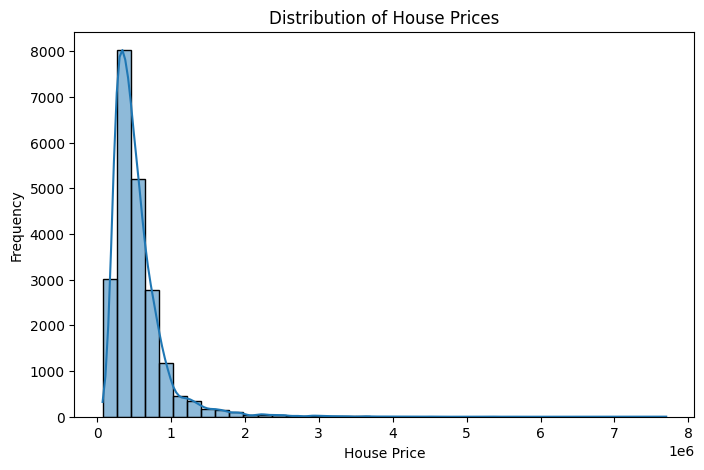

In [20]:
plt.figure(figsize=(8, 5))

sns.histplot(df['price'], bins=40, kde=True)

plt.title('Distribution of House Prices')
plt.xlabel('House Price')
plt.ylabel('Frequency')

plt.show()

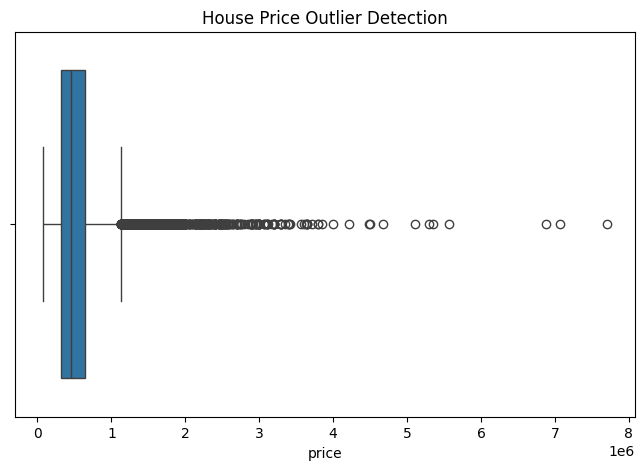

Q1: 321950.0
Q3: 645000.0
IQR: 323050.0
Lower Bound: -162625.0
Upper Bound: 1129575.0
Number of Price Outliers: 1146

Outlier Records:
         price  bedrooms  sqft_living  grade
5    1225000.0       4.0         5420     11
21   2000000.0       3.0         3050      9
49   1350000.0       3.0         2753      9
69   1325000.0       5.0         3200      8
125  1450000.0       4.0         2750      8
153  2250000.0       4.0         5180     12
216  1505000.0       5.0         3300      9
246  2400000.0       4.0         3650      9
269  2900000.0       4.0         5050     11
270  1365000.0       4.0         5310     11


In [21]:

plt.figure(figsize=(8, 5))
sns.boxplot(x=df['price'])
plt.title('House Price Outlier Detection')
plt.show()


Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[
    (df['price'] < lower_bound) |
    (df['price'] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Number of Price Outliers:", len(outliers))

print("\nOutlier Records:")
print(outliers[['price', 'bedrooms',
                'sqft_living', 'grade']].head(10))